# Campaign, crowd, cycle or counting? Growth-campaign analytics for Binance

Independent case study based on public data · not affiliated with or endorsed by Binance · Not investment advice.

Order: **real data** (Ethereum flows, campaign calendar, market) → **simulated exchange** (funnel, CAC, ROI, cohorts) → **incrementality** and methods table → **the 8 hidden events, one by one** → **monitoring and backtest** → **verification against the hidden truth** (last, and only there).

No network call: everything is read from the DuckDB warehouse (`src/run_sql.py`) and `data/processed/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import os; os.chdir(ROOT)
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import onchain_metrics as om, sim_analysis as sa, stats
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)

## Part A - Real data: Binance flows on Ethereum (PUBLIC DATA)
Deposits and withdrawals **on Ethereum only**, to and from the addresses Binance published in its Proof of Reserves. An address is not a user; a new address is not a new customer.

In [2]:
r1 = om.r1(); pd.Series(r1).round(4)

days                                     182.0000
deposits_per_day                       30831.1813
withdrawals_per_day                    50553.0330
active_deposit_addresses_per_day       18257.4286
swept_addresses_per_day                34587.9121
deposits_change_first_vs_last_4w          -0.3070
withdrawals_change_first_vs_last_4w        0.2030
usdt_share_of_deposit_transfers            0.3312
usdc_share_of_deposit_transfers            0.1547
eth_share_of_deposit_transfers             0.1889
weekend_vs_weekday                        -0.2189
peak_hour_hkt                             22.0000
trough_hour_hkt                            7.0000
peak_to_trough_hkt                         1.7643
withdrawals_to_deposits                    1.6397
dtype: float64

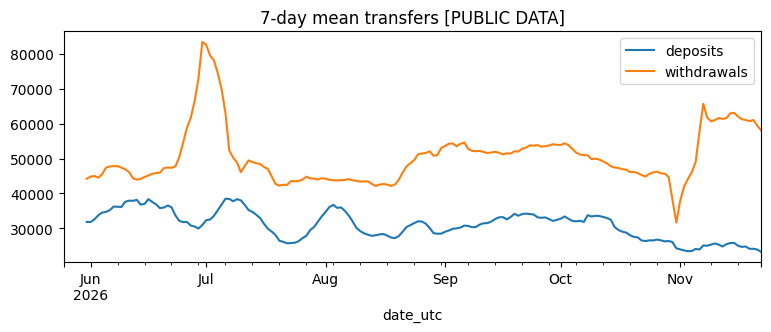

In [3]:
d = pd.read_csv('data/processed/onchain_r1_daily.csv', parse_dates=['date_utc']).set_index('date_utc')
d[['deposits', 'withdrawals']].rolling(7).mean().plot(figsize=(9, 3), title='7-day mean transfers [PUBLIC DATA]');

### R2 - Counting: three list definitions
The list grows from snapshot to snapshot. Counting with the list in force each day adds every newly published address to the trend.

In [4]:
r2 = om.r2(); pd.Series(r2).round(4)

deposits_change_A_asof        4.304000e-01
deposits_per_day_A_asof       9.705681e+03
deposits_change_B_union      -3.070000e-01
deposits_per_day_B_union      3.083118e+04
deposits_change_C_nov        -3.033000e-01
deposits_per_day_C_nov        1.893766e+04
fake_growth_pts               7.375000e-01
coverage_first4w_A_asof       1.792000e-01
coverage_last4w_A_asof        1.721000e-01
coverage_first4w_C_nov        4.634000e-01
coverage_last4w_C_nov         3.051000e-01
coverage_20nov_clean          3.279000e-01
coverage_20nov_raw            3.272000e-01
coverage_20nov_raw_listed     6.468000e+03
coverage_20nov_raw_senders    1.977000e+04
excl_failed_share             2.000000e-04
excl_zero_value_share         3.347000e-01
excl_dust_share               2.100000e-03
excl_internal_share           1.900000e-03
clean_share                   6.611000e-01
list_deposit_first            1.818261e+06
list_deposit_last             8.139203e+06
list_wallets_first            3.600000e+01
list_wallet

In [5]:
pd.read_csv('data/processed/stg_por_snapshots.csv')

,snapshot_date,n_deposit_addresses,n_hot_cold_wallets
0,2026-05-01,1818261,36
1,2026-06-01,1501978,36
2,2026-07-01,1922441,36
3,2026-08-01,2289147,36
4,2026-09-01,3227199,37
5,2026-10-01,5277755,37
6,2026-10-31,11509406,34
7,2026-11-11,8139203,111


### R3 - Address cohorts (8-week burn-in) and R4 - market

In [6]:
r3 = om.r3(); print(r3)
pd.read_csv('data/processed/onchain_r3_retention_curve.csv').round(4)

{'cohorts': 18, 'median_cohort_size': 104578.5, 'retention_w1': 0.025664376825688142, 'retention_w4': 0.020224478915936556, 'retention_w8': 0.020360537231360023, 'retention_w12': 0.03148403931587176}


,weeks_since,cohorts,addresses,retention,lo,hi
0,1,17,2735270,0.0257,0.0255,0.0259
1,2,16,2601135,0.0216,0.0214,0.0218
2,3,15,2346538,0.0197,0.0195,0.0199
3,4,14,2320307,0.0202,0.0200,0.0204
4,5,13,2281168,0.0205,0.0204,0.0207
5,6,12,2259357,0.0191,0.0189,0.0193
6,7,11,2072736,0.0191,0.0189,0.0193
7,8,10,1852014,0.0204,0.0202,0.0206
8,9,9,1523146,0.0223,0.0221,0.0226
9,10,8,1300121,0.0202,0.0199,0.0204


In [7]:
r4 = om.r4(); pd.Series(r4)

deposits_elasticity_btc_volume         0.023319
deposits_elasticity_se                 0.043166
deposits_r2                            0.334555
deposits_corr_btc_abs_return           0.206947
deposits_corr_btc_volume               0.336709
withdrawals_elasticity_btc_volume      0.038903
withdrawals_elasticity_se              0.251221
withdrawals_r2                          0.04904
withdrawals_corr_btc_abs_return        0.234426
withdrawals_corr_btc_volume             0.30626
btc_open_1oct                          83623.59
btc_open_22nov                         60215.78
btc_change_1oct_22nov                 -0.279919
most_volatile_day_sim_window         2026-09-21
most_volatile_day_abs_return           0.064886
dtype: object

### R5 - data quality of the public source

In [8]:
r5 = om.r5(); {k: v for k, v in r5.items()}

{'days': 182,
 'max_hours_late': 71.11666666666666,
 'latest_day': '2026-06-20',
 'days_late_over_6h': 14,
 'late_days': ['2026-05-29',
  '2026-05-30',
  '2026-06-20',
  '2026-06-21',
  '2026-06-22',
  '2026-07-03',
  '2026-07-15',
  '2026-07-16',
  '2026-07-25',
  '2026-07-28',
  '2026-07-29',
  '2026-08-29',
  '2026-08-31',
  '2026-09-01'],
 'duplicate_hash_days': 0,
 'duplicate_hash_rows': 0,
 'tx_total_mean': 2070324.2252747254,
 'tt_total_mean': 3695022.9285714286,
 'zero_value_share_all_transfers': 0.06022867204828554,
 'failed_share_all_tx': 0.013748764928413069,
 'mb_read_total_gb': 138.1145,
 'extract_hours_total': 4.989166666666667,
 'outlier_days_z3': 0,
 'wallet_gap_days': ['2026-10-30', '2026-10-31', '2026-11-01', '2026-11-02'],
 'wallet_gap_min_ratio': 0.0014895729890764648,
 'wallet_gap_max_ratio': 0.1216839267981274,
 'wallet_gap_deposit_ratio_mean': 0.7942144718069818}

### Second method and approximate counts

In [9]:
print(om.crosscheck_pandas())
print(om.approx_vs_exact())

[{'date': '2026-06-15', 'deposits_pandas': 12409, 'deposits_sql': 12409, 'senders_pandas': 5492, 'senders_sql': 5492, 'match': True}, {'date': '2026-09-21', 'deposits_pandas': 11335, 'deposits_sql': 11335, 'senders_pandas': 103026, 'senders_sql': 103026, 'match': True}, {'date': '2026-11-20', 'deposits_pandas': 11034, 'deposits_sql': 11034, 'senders_pandas': 12453, 'senders_sql': 12453, 'match': True}]


{'mean_abs_error': 0.09625575874173563, 'max_abs_error': 0.38975954061490614, 'seconds_exact': 0.59, 'seconds_approx': 0.06}


## Part B - Real campaign calendar (PUBLIC DATA)
Titles are never shown: code, dates, period and derived categories only.

In [10]:
cal = om.calendar_summary(); cal

{'announcements': 750,
 'since_25may': 430,
 'in_sim_window': 195,
 'first': '2025-12-08',
 'last': '2026-11-23',
 'detail_in_scope': 430,
 'detail_read': 430,
 'period_found': 372,
 'type_shares_since_25may': {'trading_competition': 0.3512,
  'other': 0.1953,
  'earn_apr': 0.1488,
  'learn_quiz': 0.0674,
  'tokenized_stock': 0.0535,
  'p2p': 0.0442,
  'referral': 0.0372,
  'new_user': 0.0372,
  'alpha': 0.0279,
  'pay': 0.0233,
  'deposit': 0.014},
 'region_stated_share': 0.07674418604651163,
 'taxonomy_dev_v1': 0.7,
 'taxonomy_dev_v2': 0.98,
 'taxonomy_fresh_v2': 0.88}

In [11]:
es = om.event_study(); print(es)
pd.read_csv('data/processed/event_study_real_campaigns.csv').round(3).head(20)

{'events': 19, 'events_usdt': 7, 'events_usdc': 12, 'share_start_from_period': 0.9473684210526315, 'significant_raw_p05': 2, 'significant_bh_q10': 0, 'mde_usdt': 0.11053998539797782, 'mde_usdc': 0.2006415475188374, 'median_abs_effect': 0.06500330801818333, 'mean_active_promotions': 36.76923076923077, 'max_active_promotions': 51}


,article_code,asset,start,start_from_period,log_effect,effect,p_placebo,mde,q_bh
0,95675adbaf01430dbcc0da662430e526,USDT,2026-06-18,True,-0.092,-0.088,0.046,0.111,0.437
1,718e3eb2f4814b2681c93fb8d029da74,USDT,2026-06-29,True,0.057,0.059,0.375,0.111,0.869
2,0d40f2d8e4d847afa2562b44d80e9c1a,USDT,2026-07-17,True,-0.085,-0.082,0.097,0.111,0.614
3,8fcf21a47f144e468656fcd205999f85,USDT,2026-07-23,True,-0.045,-0.044,0.530,0.111,0.869
4,04663ce7cbc64165b060bf4065e43299,USDT,2026-08-25,True,-0.013,-0.013,0.865,0.111,0.904
5,2d943377ecae4ef18a33cc90047a1d80,USDT,2026-09-08,True,-0.013,-0.013,0.871,0.111,0.904
6,20ffd754d7414596aa065a23e23eabbd,USDT,2026-09-25,True,0.017,0.017,0.833,0.111,0.904
7,2526d2ed10c14a34a4fa467b34c47ba2,USDC,2026-06-18,False,-0.175,-0.161,0.043,0.201,0.437
8,55baa0469bad48b08e6bc64408e279ac,USDC,2026-07-01,True,0.096,0.101,0.366,0.201,0.869
9,4b0aab00e24a40c2a88d97faa85a6aaf,USDC,2026-07-08,True,-0.023,-0.023,0.867,0.201,0.904


**Reading.** With many promotions live every day, public on-chain data cannot isolate a single campaign; the minimum detectable effect above is the honest answer.

## Part C - Simulated exchange (SIMULATED, fictional, not Binance)

In [12]:
json.loads((ROOT / 'data/sim/_meta.json').read_text())

{'seed': 42,
 'scale': 1.0,
 'signups': 1365325,
 'rows_total': 24674686,
 'competition_day': '2026-09-21',
 'market_k': 0.1845,
 'held_invoice_share': 0.1555}

In [13]:
sa.q('SELECT * FROM funnel_by_region_channel').groupby('region')[['registrations','kyc_passed','first_deposit_7d']].sum().assign(conv=lambda x: x.first_deposit_7d / x.registrations).round(3)

,registrations,kyc_passed,first_deposit_7d,conv
region,,,,
CIS-KZ,61764.0,35574.0,18799.0,0.304
EU,214842.0,123794.0,65109.0,0.303
LATAM-AR,82140.0,47397.0,25121.0,0.306
LATAM-BR,202431.0,117178.0,67683.0,0.334
LATAM-MX,101390.0,58491.0,31179.0,0.308
MENA,134879.0,77746.0,41193.0,0.305
SEA-PH,121880.0,70455.0,37116.0,0.305
SEA-VN,190413.0,107242.0,56895.0,0.299
TR,163750.0,92238.0,48404.0,0.296


In [14]:
sa.q('SELECT campaign_id, type, region, attributed_first_depositors, cac_first_deposit, roi_30d, retention_d30, share_withdrew_90pct_30d FROM campaign_kpis ORDER BY cac_first_deposit')

,campaign_id,type,region,attributed_first_depositors,cac_first_deposit,roi_30d,retention_d30,share_withdrew_90pct_30d
0,CMP014,new_user,LATAM-BR,25024,9.00,-0.5790,0.0635,0.5484
1,CMP016,referral,MENA,1582,23.10,0.7308,0.3546,0.0563
2,CMP036,learn_quiz,LATAM-AR,103,23.55,0.5913,0.4078,0.0777
3,CMP003,learn_quiz,SEA-VN,1083,31.17,0.3007,0.3601,0.0489
4,CMP005,new_user,TR,278,31.39,0.0717,0.3129,0.0791
5,CMP011,learn_quiz,MENA,2175,32.46,0.2423,0.3776,0.0561
6,CMP004,new_user,LATAM-AR,153,36.94,0.0648,0.3504,0.0365
7,CMP017,new_user,TR,582,45.61,-0.1338,0.3608,0.0601
8,CMP038,new_user,SEA-VN,1200,49.92,-0.1869,0.3550,0.0550
9,CMP024,learn_quiz,CIS-KZ,301,51.66,NaN,NaN,NaN


In [15]:
t = sa.q('SELECT channel, days, observed FROM time_to_first_deposit')
km = stats.kaplan_meier(t.days.values, t.observed.values)
print('median days from KYC to first deposit:', km.loc[km.survival <= 0.5, 't'].iloc[0])

median days from KYC to first deposit: 5.040162037037037


## Part D - Incrementality: four methods per campaign

In [16]:
rows = []
for cid in sa.campaigns().campaign_id:
    r = sa.incrementality(cid)
    rows.append({'campaign': cid, 'outcome': r.get('outcome', 'holdout'),
                 **{m: round(r[m]['effect'], 3) for m in ('naive', 'did', 'synthetic') if m in r},
                 'placebo_time': round(r['placebo_time']['effect'], 3) if 'placebo_time' in r else None,
                 'note': r.get('note', '')})
inc = pd.DataFrame(rows); inc

,campaign,outcome,naive,did,synthetic,placebo_time,note
0,CMP001,repeat_deposits,0.239,0.004,0.041,-0.058,
1,CMP002,repeat_deposits,3.403,0.226,0.149,NaN,
2,CMP003,signups (organic),0.009,-0.009,-0.021,NaN,
3,CMP004,signups (paid_search),0.123,0.159,0.171,0.085,
4,CMP005,signups (paid_social),0.089,0.173,0.223,0.067,
5,CMP006,signups (referral),0.617,0.605,0.608,NaN,
6,CMP007,repeat_deposits,1.093,0.180,0.171,NaN,
7,CMP008,trades,3.547,0.088,0.065,NaN,
8,CMP009,holdout,NaN,NaN,NaN,NaN,CRM campaign: measured with its randomised hol...
9,CMP010,signups (organic),0.095,0.109,0.105,0.008,


In [17]:
pd.DataFrame([sa.crm_experiment(c) for c in sa.campaigns().query('has_holdout').campaign_id]).round(4)

,campaign_id,n_treatment,n_holdout,srm_p,rate_treatment,rate_holdout,diff,diff_lo,diff_hi,p,cuped_diff,cuped_lo,cuped_hi,variance_reduction,mde_pts
0,CMP009,179994,20006,0.9643,0.0854,0.0793,0.0062,0.0022,0.0101,0.0030,0.0046,0.0011,0.0082,0.1871,0.0057
1,CMP020,179982,20018,0.8933,0.0789,0.0782,0.0007,-0.0032,0.0046,0.7334,0.0001,-0.0034,0.0036,0.1930,0.0056
2,CMP031,539830,60170,0.4644,0.0955,0.0775,0.0180,0.0157,0.0203,0.0000,0.0175,0.0155,0.0196,0.1636,0.0033
3,CMP035,180104,19896,0.4382,0.0892,0.0786,0.0106,0.0066,0.0145,0.0000,0.0102,0.0067,0.0138,0.1745,0.0057


## Part E - The 8 hidden events, recovered from the data (no truth read here)

In [18]:
ev = sa.events()

### 1. LATAM-BR boosted-rate campaign (CMP014): best CAC, negative ROI
Read CAC, then the costs it leaves out (promo bonus), then the crowd: retention and full withdrawals.

In [19]:
ev['E1']

{'cac': 9.0,
 'cac_rank': 1,
 'roi_30d': -0.579,
 'withdrew_90pct': 0.5484,
 'retention_d30': 0.0635,
 'signup_lift_naive': 1.2987853096358521,
 'median_roi_others': -0.0345,
 'n_kpi_campaigns': 14}

### 2. Referral farm (week of 14 Sep): indicators only

In [20]:
print(ev['E2'])
sa.q('SELECT * FROM referral_abuse_indicators ORDER BY flags DESC LIMIT 5')

{'flagged_referrers': 41, 'flagged_referees': 6202, 'referral_signups_week': 26426, 'flagged_in_week': 6201, 'inflation': 0.30660074165636586, 'median_flags_others': None}


,referrer_id,referees,share_shared_device,max_referees_60min,kyc_pass_share,share_identical_first_deposit,flags
0,U3000022,177,1.0,10,0.1412,1.0,4
1,U3000008,164,1.0,10,0.1585,1.0,4
2,U3000033,163,1.0,10,0.1840,1.0,4
3,U3000003,157,1.0,10,0.1146,1.0,4
4,U3000026,144,1.0,10,0.1389,1.0,4


### 3. Double-counted attribution (LATAM)

In [21]:
print(ev['E3'])
sa.q('SELECT * FROM partner_claims')

{'latam_claimed_over_real': 1.2868, 'other_claimed_over_real': 1.1901}


,region_group,claimed_affiliate_kol,claimed_paid_social,claimed_total,real_signups_touched,claimed_over_real,last_touch_credit
0,LATAM,179754.0,183957.0,363711.0,282638,1.2868,158371
1,other,328927.0,408763.0,737690.0,619846,1.1901,301494


### 4. KYC vendor outage in TR (6-8 Oct): the campaign was not the problem

In [22]:
ev['E4']

{'pass_rate_outage': 0.22468642065079075,
 'pass_rate_before': 0.7749304727850616,
 'cmp017_first_depositors': 582}

### 5. Data quality: duplicated deposits (27 Oct) and the UTC vs UTC+8 launch day

In [23]:
ev['E5']

{'raw_rows_27oct': 20546,
 'clean_rows_27oct': 9784,
 'ratio': 2.099959116925593,
 'late_launch_campaign': 'CMP027',
 'launch_ts_utc': '2026-11-02 16:00:00',
 'day1_deposits_utc': 1060,
 'day1_deposits_hkt': 1029}

### 6. A market-made success: the trading competition on the most volatile BTC day

In [24]:
ev['E6']

{'naive': np.float64(0.6464037069813853),
 'did': np.float64(0.05327906385627798),
 'did_lo': np.float64(0.015959091362264786),
 'did_hi': np.float64(0.09196993834703042),
 'start': '2026-09-21',
 'naive_3d_vs_7d': 0.46392041474008683}

### 7. Simpson: retention down overall, up in every channel

In [25]:
print(ev['E7'])
sa.q("SELECT * FROM retention_by_channel_month WHERE dep_month IN ('2026-09-01','2026-10-01')")

{'overall_sep': 0.3115, 'overall_oct': 0.2542, 'channels_up': 6, 'channels': 6, 'affiliate_share_sep': 0.07255005977877893, 'affiliate_share_oct': 0.3837450526420131, 'standardised_sep': 0.26873628221996293, 'standardised_oct': 0.2944887809491059}


,dep_month,channel,depositors_full_30d,retention_d7,retention_d30
0,2026-09-01,ALL,126299,0.7158,0.3115
1,2026-09-01,affiliate_kol,9163,0.6779,0.0704
2,2026-09-01,app_store_ads,17911,0.7172,0.2840
3,2026-09-01,organic,38132,0.7294,0.3646
4,2026-09-01,paid_search,16447,0.7232,0.3386
5,2026-09-01,paid_social,15132,0.7164,0.2822
6,2026-09-01,referral,29514,0.7049,0.3341
7,2026-10-01,ALL,141237,0.7109,0.2542
8,2026-10-01,affiliate_kol,54199,0.6791,0.0855
9,2026-10-01,app_store_ads,13333,0.7169,0.3122


### 8. False signal: CAC +40% week over week (2 Nov) - dismissed with evidence

In [26]:
print(ev['E8'])
sa.q('SELECT week, cac_activity, cac_booking, wow_activity, wow_booking FROM cac_weekly')

{'wow_booking': 0.4001, 'wow_activity': -0.2277, 'cac_booking': 22.85, 'cac_activity': 11.43}


,week,cac_activity,cac_booking,wow_activity,wow_booking
0,2026-08-24,19.52,16.54,NaN,NaN
1,2026-08-31,12.40,12.50,-0.3648,-0.2443
2,2026-09-07,15.78,15.78,0.2726,0.2624
3,2026-09-14,15.73,15.66,-0.0032,-0.0076
4,2026-09-21,16.71,16.69,0.0623,0.0658
5,2026-09-28,19.02,14.13,0.1382,-0.1534
6,2026-10-05,20.09,14.95,0.0563,0.0580
7,2026-10-12,18.08,17.92,-0.1000,0.1987
8,2026-10-19,18.45,16.99,0.0205,-0.0519
9,2026-10-26,14.80,16.32,-0.1978,-0.0394


## Part F - Monitoring: control charts, CUSUM and a 13-week backtest

In [27]:
alerts = sa.monitoring_backtest(); alerts

,series,date,detail
0,cac_booking_weekly,2026-09-07,WoW +26%
1,cac_activity_weekly,2026-09-07,WoW +27%
2,cac_booking_weekly,2026-11-02,WoW +40%
3,kyc_pass_rate_LATAM-BR,2026-11-10,75% < 75%
4,kyc_pass_rate_LATAM-BR,2026-11-20,74% < 75%
5,kyc_pass_rate_TR,2026-10-06,21% < 74%
6,kyc_pass_rate_TR,2026-10-07,21% < 74%
7,kyc_pass_rate_TR,2026-10-08,25% < 74%
8,deposits_raw_daily,2026-10-27,"20,546 > 1.5 x 10,067"
9,deposits_raw_daily,2026-11-14,"13,874 > 1.5 x 8,982"


## Part G - Verification against the hidden truth (only here)

In [28]:
det, summ = sa.methods_vs_truth(); summ.round(3)

,method,campaigns,mean_abs_error,mean_error,coverage
0,did,33,0.073,0.003,0.576
1,naive,36,0.855,0.826,0.361
2,randomised_holdout,4,0.001,-0.000,1.000
3,synthetic,33,0.076,0.013,0.727


In [29]:
scored = sa.score_backtest(alerts); print(scored.label.value_counts().to_dict(), 'missed:', scored.attrs['missed'])

{'true alert': 7, 'false alert': 3, 'explained false alert': 1} missed: ['referral farm (week of 14 Sep)']


In [30]:
sa.truth().query("kind == 'event'")

,kind,key,metric,true_lift,true_incremental,counterfactual
18,event,E1_brazil_bonus_hunters,hunter_share_of_cmp014_depositors,0.8000,12899.0,25024
19,event,E2_referral_farm,farm_accounts_vs_genuine_referral_signups_week,0.3065,6200.0,20226
20,event,E3_latam_double_counting,claims_over_touched_signups,1.2868,363711.0,282638
21,event,E4_tr_kyc_outage,kyc_pass_rate_outage,0.2200,7367.0,0.78
22,event,E5a_duplicate_deposits,duplicate_rows_2026-10-27,2.1000,10762.0,9784
23,event,E5b_utc_vs_utc8_launch,campaign,0.0000,0.0,CMP027
24,event,E6_market_false_success,true_trade_lift_CMP022,0.0300,28.0,0.1845
25,event,E7_simpson_retention,channel_uplift_oct,0.0400,0.0,6.5
26,event,E8_booking_vs_activity,held_invoice_share,0.1555,0.0,2026-11-02
